In [2]:
#importe das bibliotecas utilizadas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time


FPS: 30.0
Duração: 9.533333333333333 segundos
Resolução: 1920x1080
Pixels por quadro: 2073600
Total de quadros: 286
Total de pixels no vídeo: 593049600
Quantidade de quadros: 286
Dimensão de cada quadro: (120, 160)
Dimensão da matriz M: (19200, 286)
[[ 39.  34.  29. ...  64.  64.  64.]
 [ 60.  64.  63. ...  15.  15.  15.]
 [ 26.  25.  24. ...  74.  74.  74.]
 ...
 [ 97. 105. 105. ... 133. 133. 126.]
 [131. 133. 133. ... 110. 111. 109.]
 [135. 126. 126. ... 138. 137. 136.]]


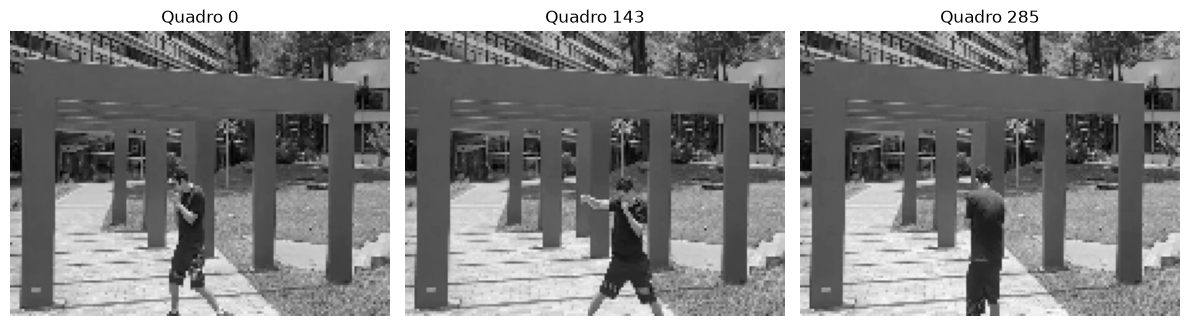

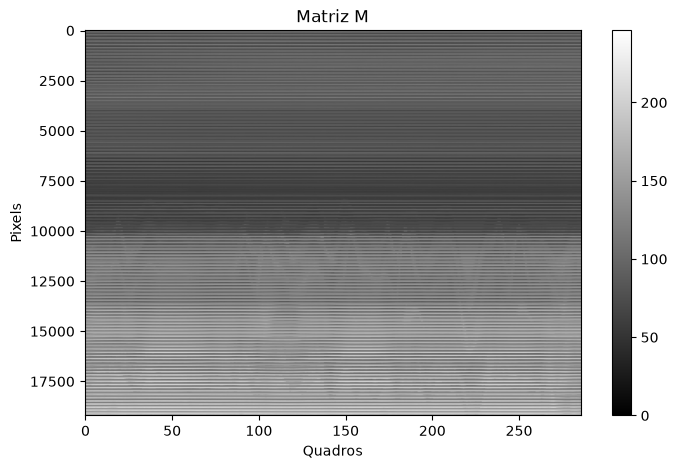

In [4]:
#Processamento de imagem usando open-cv (PRINCIPAL)

# 1. Abrir o vídeo
video = cv2.VideoCapture("data/teste2.mp4")

# Informações do vídeo
fps = video.get(cv2.CAP_PROP_FPS)
total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

duracao = total_frames / fps

largura = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
pixels_por_frame = largura * altura
total_pixels_video = pixels_por_frame * total_frames

print("FPS:", fps)
print("Duração:", duracao, "segundos")

print(f"Resolução: {largura}x{altura}")
print(f"Pixels por quadro: {pixels_por_frame}")
print(f"Total de quadros: {total_frames}")
print(f"Total de pixels no vídeo: {total_pixels_video}")

# 2. Extrair e processar os quadros
frames = []

while True:
    ret, frame = video.read()

    if not ret:
        break

    # Converter para escala de cinza
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Redimensionar os quadros
    gray = cv2.resize(gray, (160, 120))

    frames.append(gray)

video.release()

# 3. Verificar os quadros
print("Quantidade de quadros:", len(frames))
print("Dimensão de cada quadro:", frames[0].shape)

# 4. Vetorizar cada quadro
vetores = [frame.flatten() for frame in frames]

# 5. Construir a matriz M
M = np.column_stack(vetores).astype(float)

print("Dimensão da matriz M:", M.shape)
print(M)

# 6. Visualizar alguns quadros
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

indices = [0, len(frames)//2, len(frames)-1]

for ax, idx in zip(axes, indices):
    ax.imshow(frames[idx], cmap='gray')
    ax.set_title(f"Quadro {idx}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# 7. Visualizar a matriz M
plt.figure(figsize=(8, 5))
plt.imshow(M, cmap='gray', aspect='auto')
plt.title("Matriz M")
plt.xlabel("Quadros")
plt.ylabel("Pixels")
plt.colorbar()
plt.show()


#Função para obter matriz M, resumindo alguns passos anteriores dentro de uma única função:


def obter_matriz_M(caminho_video, largura=160, altura=120):

    # Abrir o vídeo
    video = cv2.VideoCapture(caminho_video)

    if not video.isOpened():
        raise Exception("Não foi possível abrir o vídeo!")

    # Extrair os quadros
    frames = []

    while True:
        ret, frame = video.read()

        if not ret:
            break

        # Converter para escala de cinza
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Redimensionar os quadros
        gray = cv2.resize(gray, (largura, altura))

        frames.append(gray)

    video.release()

    # Verificar se foram extraídos quadros
    if len(frames) == 0:
        raise Exception("Nenhum quadro foi extraído!")

    # Vetorizar cada quadro
    vetores = [frame.flatten() for frame in frames]

    # Construir a matriz M
    M = np.column_stack(vetores).astype(float)

    return M



In [ ]:
#Funções de decomposição SVD

'''Decomposicao SVD'''
'''Parte 2: Joao Pedro Gomes Araujo Munhoz Ribeiro'''

import numpy as np
import time

EPS = np.finfo(float).eps


# Definicao da matriz devidamente formatada: M = A A^T
def Matriz(A):
    return A @ A.T


# Decompoe as matrizes Q e R
def Matrizes_Q_R(M):
    Q, R = np.linalg.qr(M)
    return Q, R


# Calculo dos valores singulares 
def Singulares_QR(B, tol=1e-15, max_iter=5000):
    W = np.array(B, dtype=float)

    for k in range(max_iter):
        Qk, Rk = Matrizes_Q_R(W)
        W = Rk @ Qk
      
        off = np.linalg.norm(W - np.diag(np.diag(W)))
        if off <= tol * np.linalg.norm(W):
            break

    lam = np.diag(W).real
    lam = np.maximum(lam, 0.0)         
    autoval = np.sqrt(lam)
    return np.sort(autoval)[::-1]


#Calculo dos Autovetores da direita
def Autovetores_Direita(A, autv, tol=1e-15, iter=100):
    A = np.array(A, dtype=float)
    n = A.shape[0]
    I = np.eye(n)
    normaA = np.linalg.norm(A)
    rng = np.random.default_rng(0)
    autovetores = []

    for k in range(n):
        lam = autv[k] ** 2                      
        mu = lam + 10 * EPS * normaA             
        B = A - mu * I

        qold = rng.random(n) - 0.5
        qold /= np.linalg.norm(qold)

        norm = 1
        cont = 0
        while norm > tol and cont < iter:
            try:
                qnew = np.linalg.solve(B, qold)
            except np.linalg.LinAlgError:
                mu += 10 * EPS * normaA
                B = A - mu * I
                continue

            for _ in range(2):
                for q in autovetores:
                    qnew = qnew - np.dot(q, qnew) * q

            qnew = qnew / np.linalg.norm(qnew)
            norm = 1 - np.abs(np.vdot(qold, qnew))
            qold = qnew
            cont += 1

        autovetores.append(qold)                 

    return np.array(autovetores)                

#Calculo dos autovetores da esquerda
def Autovetores_esquerda(A, autovec, autoval):
    n = len(autoval)
    v = []
    sig = np.zeros(n)
    for i in range(n):
        w = A.T @ autovec[i]
        sig[i] = np.linalg.norm(w)              
        v.append(w / sig[i] if sig[i] > 0 else w)
    v = np.array(v)

    
    for i in range(n):
        for _ in range(2):
            for j in range(i):
                v[i] = v[i] - np.dot(v[j], v[i]) * v[j]
        nv = np.linalg.norm(v[i])
        if nv > 0:
            v[i] = v[i] / nv
    return v, sig

#Definicao das matrizes
def Matrizes(A, AutovecL, AutovecR, Autoval):
    n = A.shape[0]
    S = np.eye(n)
    for j in range(n):
        S[j][j] = Autoval[j]

    U = np.array(AutovecL).T      
    Vt = np.array(AutovecR)        
    return U, S, Vt

#Funcao final
def DecompsicaoSVD(A):
    A = np.array(A, dtype=float)
    inicio = time.perf_counter()
    M = Matriz(A)
    ValoresSingulares = Singulares_QR(M)
    U_vec = Autovetores_Direita(M, ValoresSingulares)          
    V_vec, sig = Autovetores_esquerda(A, U_vec, ValoresSingulares)  
    U, S, Vt = Matrizes(A, U_vec, V_vec, sig)
    fim = time.perf_counter()
    return U, S, Vt, fim - inicio

In [6]:
# Comparacao com o svd nativo:

A = np.array([[1, 2, 3], [9, 0, 7], [2, 5, 0]], dtype=float)

u, s, v, t = DecompsicaoSVD(A)

inip = time.perf_counter()
m, n, p = np.linalg.svd(A)
fimp = time.perf_counter()
tp = fimp - inip

print("Minha solucao:\nU =\n", u, "\nS =\n", s, "\nVt =\n", v)
print("Tempo da minha solucao:", t)
print("Solucao do programa:\nU =\n", m, "\nS =\n", n, "\nVt =\n", p, "\nT = ", tp)

print("Erro na aproximacao:\n")

eU = m - u
eS = np.dot(n, np.eye(A.shape[0])) - s
eV = v - p

print("Erro de U:\n ", eU)
print("Erro de S:\n ", eS)
print("Erro de V:\n ", eV)

Minha solucao:
U =
 [[-0.24217417  0.27582641  0.93019969]
 [-0.95354174 -0.24473231 -0.17568222]
 [-0.17919212  0.92952993 -0.32227984]] 
S =
 [[11.87441822  0.          0.        ]
 [ 0.          5.274628    0.        ]
 [ 0.          0.          2.04364658]] 
Vt =
 [[-0.77329549 -0.11624224 -0.62329914]
 [-0.01283588  0.98571927 -0.16790699]
 [-0.63391586  0.12184113  0.76374434]]
Tempo da minha solucao: 0.04127719600001001
Solucao do programa:
U =
 [[-0.24217417 -0.27582641  0.93019969]
 [-0.95354174  0.24473231 -0.17568222]
 [-0.17919212 -0.92952993 -0.32227984]] 
S =
 [11.87441822  5.274628    2.04364658] 
Vt =
 [[-0.77329549 -0.11624224 -0.62329914]
 [ 0.01283588 -0.98571927  0.16790699]
 [-0.63391586  0.12184113  0.76374434]] 
T =  0.005401275000622263
Erro na aproximacao:

Erro de U:
  [[-4.99600361e-16 -5.51652811e-01  2.22044605e-16]
 [ 0.00000000e+00  4.89464613e-01  1.94289029e-16]
 [ 0.00000000e+00 -1.85905986e+00 -1.66533454e-16]]
Erro de S:
  [[3.55271368e-15 5.27462800

In [ ]:
# Parte 3 APROXIMAÇÃO DE BAIXO POSTO 
def aproximacao_baixo_posto(U, S, Vt, k):
    # Calcula a aproximação de posto no máximo k (Eq. 11):
    # Garante que os valores singulares estejam em um vetor 1D
    s = np.diag(S) if S.ndim == 2 else S
    r = len(s)

    if not (1 <= k <= r):
        raise ValueError(f"k deve estar entre 1 e {r}.")

    # Mantém apenas os k maiores valores singulares e seus vetores correspondentes
    U_k = U[:, :k]
    Sigma_k = np.diag(s[:k])
    Vt_k = Vt[:k, :]

    L_k = U_k @ Sigma_k @ Vt_k
    return L_k


def avaliar_aproximacao(M, L_k, s=None, k=None):
    """
    Calcula o erro na norma de Frobenius ||M - L_k||_F (Eq. 12)
    e o erro relativo percentual.
    """
    erro_frob = np.linalg.norm(M - L_k, ord='fro')
    norma_M = np.linalg.norm(M, ord='fro')
    erro_relativo = erro_frob / norma_M

    resultado = {
        "erro_frobenius": erro_frob,
        "erro_relativo": erro_relativo,
    }

    # Verificação teórica: ||M - L_k||_F = sqrt(sum_{i=k+1}^r sigma_i^2)
    if s is not None and k is not None:
        s_vec = np.diag(s) if s.ndim == 2 else s
        resultado["erro_teorico_sigmas"] = np.sqrt(np.sum(s_vec[k:] ** 2))

    return resultado

# 1. Obter a matriz M do vídeo
largura, altura = 160, 120
M = obter_matriz_M("data/teste2.mp4", largura=largura, altura=altura)

# 2. Calcular a SVD reduzida de M (M = U @ diag(s) @ Vt)
U, s, Vt = np.linalg.svd(M, full_matrices=False)
r = len(s)
print(f"Dimensão de M: {M.shape} | Posto máximo r: {r}")

# 3. Testar diferentes valores de posto k <= r (arbitrários)
valores_k = [1, 2, 3, 4, 5, 10, 20, 100]
valores_k = [k for k in valores_k if k <= r]

aproximacoes = {}
for k in valores_k:
    L_k = aproximacao_baixo_posto(U, s, Vt, k)
    metricas = avaliar_aproximacao(M, L_k, s=s, k=k)
    aproximacoes[k] = L_k

    print(
        f"k = {k:2d} | "
        f"||M - L_k||_F = {metricas['erro_frobenius']:.4f} | "
        f"Teórico = {metricas['erro_teorico_sigmas']:.4f} | "
        f"Erro relativo = {metricas['erro_relativo']*100:.2f}%"
    )

Dimensão de M: (19200, 286) | Posto máximo r: 286
k =  1 | ||M - L_k||_F = 39408.2242 | Teórico = 39408.2242 | Erro relativo = 14.12%
k =  2 | ||M - L_k||_F = 34116.2918 | Teórico = 34116.2918 | Erro relativo = 12.22%
k =  3 | ||M - L_k||_F = 29667.3261 | Teórico = 29667.3261 | Erro relativo = 10.63%
k =  4 | ||M - L_k||_F = 27629.4695 | Teórico = 27629.4695 | Erro relativo = 9.90%
k =  5 | ||M - L_k||_F = 26298.0019 | Teórico = 26298.0019 | Erro relativo = 9.42%
k = 10 | ||M - L_k||_F = 22448.2125 | Teórico = 22448.2125 | Erro relativo = 8.04%
k = 20 | ||M - L_k||_F = 18788.7216 | Teórico = 18788.7216 | Erro relativo = 6.73%
k = 100 | ||M - L_k||_F = 9917.9439 | Teórico = 9917.9439 | Erro relativo = 3.55%


[1, 2, 3, 4, 5, 10, 20, 100]


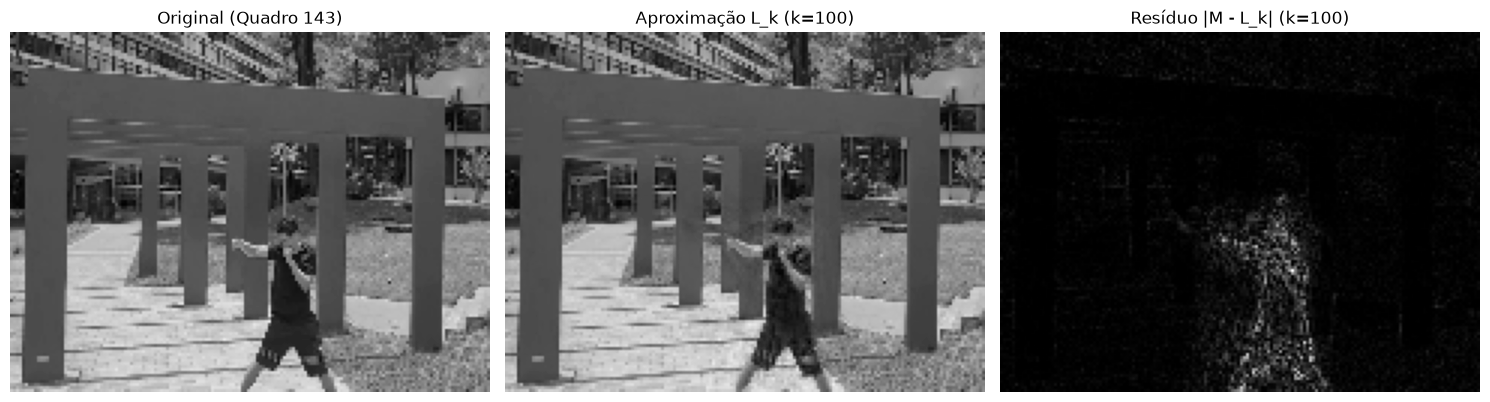

In [ ]:
print(valores_k)

# Visualização dos quadros reconstruídos (Lk e do resíduo (M - Lk))
idx_quadro = M.shape[1] // 2  # Quadro central do vídeo (PRA TESTE)
k_escolhido = valores_k[0]    # Defina o k que deseja de 0 a 7 (1, 2, 3, 4, 5, 10, 20, 100)
L_k = aproximacoes[k_escolhido] # influencia no quão bom é o recorte 

quadro_original = M[:, idx_quadro].reshape((altura, largura))
quadro_Lk = np.clip(L_k[:, idx_quadro].reshape((altura, largura)), 0, 255)
quadro_residuo = np.abs(M[:, idx_quadro] - L_k[:, idx_quadro]).reshape((altura, largura))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(quadro_original, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f"Original (Quadro {idx_quadro})")
axes[0].axis('off')

axes[1].imshow(quadro_Lk, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Aproximação L_k (k={k_escolhido})")
axes[1].axis('off')

axes[2].imshow(quadro_residuo, cmap='gray')
axes[2].set_title(f"Resíduo |M - L_k| (k={k_escolhido})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Parte 4: Identificação de Movimento
# Caio Lucas Indalécio

def mat_res(M, L_k):
    R_k = M - L_k # Dada uma matriz e um L_k, calcula-se o resíduo R_k (movimento)
    S_k = np.abs(R_k) # S_k é uma matriz cujos elementos são o módulo dos elementos de R_k
    return R_k, S_k

# Criando uma mascara binária
def mask(S_k):
    threshold = 50
    # Mask é uma matriz que transforma os valores acima de um limiar em 1 e abaixo ou igual em zero
    # Mask é, portanto, uma máscara binária.
    mask = (S_k > threshold).astype(np.uint8)
    return mask

# Nota-se que quanto maior o threshold